# 11 · Earnings quality, manipulation risk, cost stickiness and tax rates
Accounting-based diagnostics used by auditors, lenders and short sellers, applied across 123 countries:
1. **Accruals** (Sloan 1996): how much of profit is not backed by cash, and does the market of fundamentals treat it as less persistent?
2. **Discretionary accruals** (modified Jones model, Dechow, Sloan & Sweeney 1995), estimated by country, industry and year.
3. **Beneish (1999) M-score:** the share of firm-years flagged as possible earnings manipulators, and whether a flag predicts weaker results.
4. **Cost stickiness** (Anderson, Banker & Janakiraman 2003): do SG&A costs fall as fast when sales fall as they rise when sales rise?
5. **Effective tax rates** by country and over time, including the US 2018 tax reform.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
# raw statement items, same rows and order as the panel (scripts/build_panel.py); private, never published
r = pd.read_parquet(PANEL.with_name("panel_raw.parquet"))
assert (r[["gvkey", "fyear"]].to_numpy() == p[["gvkey", "fyear"]].to_numpy()).all()
p = pd.concat([p, r.drop(columns=["gvkey", "fyear"]).add_prefix("x_")], axis=1)
def wins(s, by=None, lo=0.01, hi=0.99):
    s = s.replace([np.inf, -np.inf], np.nan); by = p.loc[s.index, "fyear"] if by is None else by
    return s.clip(s.groupby(by).transform(lambda v: v.quantile(lo)), s.groupby(by).transform(lambda v: v.quantile(hi)), axis=0)
p = p.sort_values(["gvkey", "fyear"]).reset_index(drop=True)
def lag(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(k); gap = p["fyear"] - g["fyear"].shift(k)
    return v.where(gap == k)
def lead(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(-k); gap = g["fyear"].shift(-k) - p["fyear"]
    return v.where(gap == k)
A1 = lag("x_at"); p["A1"] = A1.where(A1 > 0)
p["ta"] = wins((p.x_ib - p.x_oancf) / p.A1)                    # total accruals scaled by lagged assets
p["cfo"] = wins(p.x_oancf / p.A1); p["earn"] = wins(p.x_ib / p.A1)
p["earn_next"] = lead("earn")
print(f"accruals available for {p.ta.notna().mean():.0%} of firm-years (operating cash flow reported)")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


accruals available for 89% of firm-years (operating cash flow reported)


## 1 · Accruals and earnings persistence

In [2]:
acc = aggregate.summary(p, "region", ["ta", "cfo", "earn"]).reindex(REG_ORDER); acc[["ta", "cfo", "earn"]] *= 100
rows = []
for reg_, d in p.dropna(subset=["earn_next", "cfo", "ta"]).groupby("region"):
    X = np.column_stack([np.ones(len(d)), d.cfo, d.ta]); b = np.linalg.lstsq(X, d.earn_next, rcond=None)[0]
    rows.append((reg_, b[1], b[2]))
pers = pd.DataFrame(rows, columns=["region", "cash-flow persistence", "accrual persistence"]).set_index("region").reindex(REG_ORDER)
pers["accrual discount"] = pers["cash-flow persistence"] - pers["accrual persistence"]
out = acc.join(pers); out.to_csv(DATA / "accruals_by_region.csv")
out.rename(columns={"ta": "accruals % assets", "cfo": "cash flow % assets", "earn": "earnings % assets"}).round(2)

,accruals % assets,cash flow % assets,earnings % assets,firms,firm_years,cash-flow persistence,accrual persistence,accrual discount
region,,,,,,,,
North America,-6.77,6.53,1.41,13908,117385,0.86,0.53,0.33
Western Europe,-4.94,6.63,2.49,8453,94514,0.77,0.46,0.31
Japan,-3.38,5.81,2.53,4261,58598,0.66,0.47,0.19
Other developed Asia-Pacific,-3.68,4.45,2.38,9465,113375,0.75,0.51,0.24
China,-1.37,6.09,4.87,4704,58149,0.63,0.49,0.14
India,-2.37,5.25,2.93,3673,54194,0.50,0.52,-0.03
OIC members,-2.73,5.69,3.81,3511,48831,0.63,0.54,0.10
Other emerging,-3.70,7.20,4.23,4817,62753,0.65,0.52,0.13


## 2 · Discretionary accruals (modified Jones)
TA/A₋₁ = a·(1/A₋₁) + b·(ΔSales − ΔReceivables)/A₋₁ + c·PPE/A₋₁ + e, estimated separately for every country × industry group × year with at least 15 firms. |e| measures how much of the accrual is not explained by growth and fixed assets.

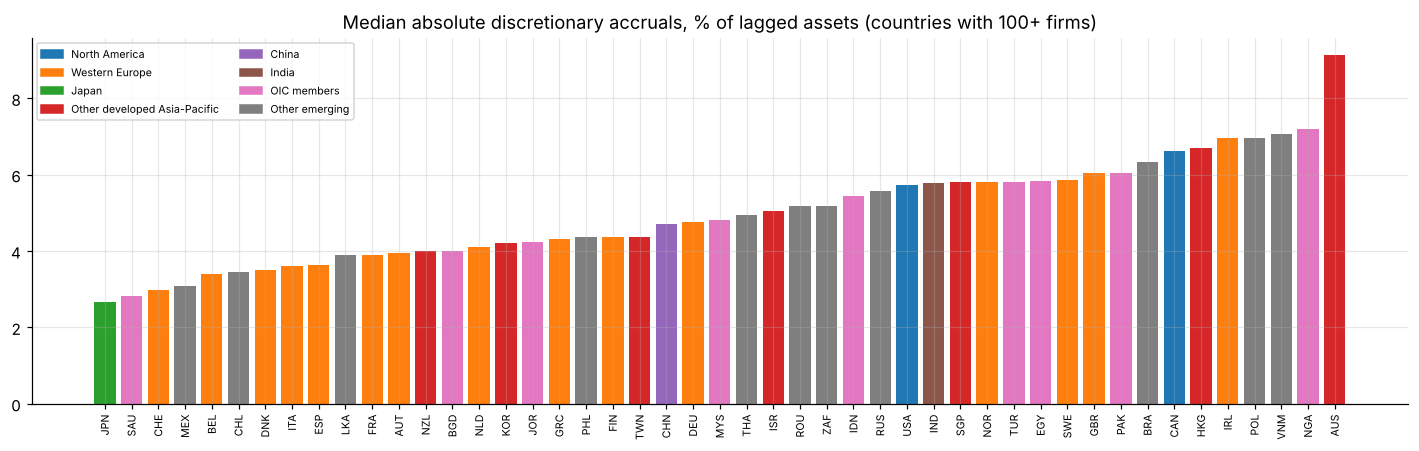

47 countries; Spearman correlation with GDP per capita: -0.09


In [3]:
p["x1"] = 1 / p.A1; p["x2"] = (p.x_sale - lag("x_sale") - (p.x_rect - lag("x_rect"))) / p.A1; p["x3"] = p.x_ppent / p.A1
for c in ["x1", "x2", "x3"]: p[c] = wins(p[c])
p["da"] = np.nan
for _, d in p.dropna(subset=["ta", "x1", "x2", "x3"]).groupby(["loc", "industry_group", "fyear"]):
    if len(d) < 15: continue
    X = d[["x1", "x2", "x3"]].to_numpy(); b = np.linalg.lstsq(X, d.ta.to_numpy(), rcond=None)[0]
    p.loc[d.index, "da"] = d.ta - X @ b
p["abs_da"] = p.da.abs()
da = aggregate.summary(p, "loc", ["abs_da", "gdp_pc"], min_firms=100).sort_values("abs_da")
da["region"] = da.index.map(p.groupby("loc").region.first()); da["abs_da"] *= 100; da.to_csv(DATA / "discretionary_accruals_by_country.csv")
fig, ax = plt.subplots(figsize=(13, 4.2))
cols_ = da.region.map(dict(zip(REG_ORDER, sns.color_palette("tab10", 8))))
ax.bar(da.index, da.abs_da, color=cols_); ax.set_title("Median absolute discretionary accruals, % of lagged assets (countries with 100+ firms)")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=r_) for r_, c in zip(REG_ORDER, sns.color_palette("tab10", 8))], fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(IMG / "discretionary_accruals.png", bbox_inches="tight"); plt.show()
print(f"{len(da)} countries; Spearman correlation with GDP per capita: {da[['abs_da', 'gdp_pc']].corr('spearman').iloc[0, 1]:.2f}")

## 3 · Beneish M-score
M = −4.84 + 0.920·DSRI + 0.528·GMI + 0.404·AQI + 0.892·SGI + 0.115·DEPI − 0.172·SGAI + 4.679·TATA − 0.327·LVGI. Firm-years with M > −1.78 are flagged. The score is a screen for further review, not evidence of manipulation. Index components are winsorised at the 1st and 99th percentiles by year.

M-score computable for 77% of firm-years; 17.6% flagged overall


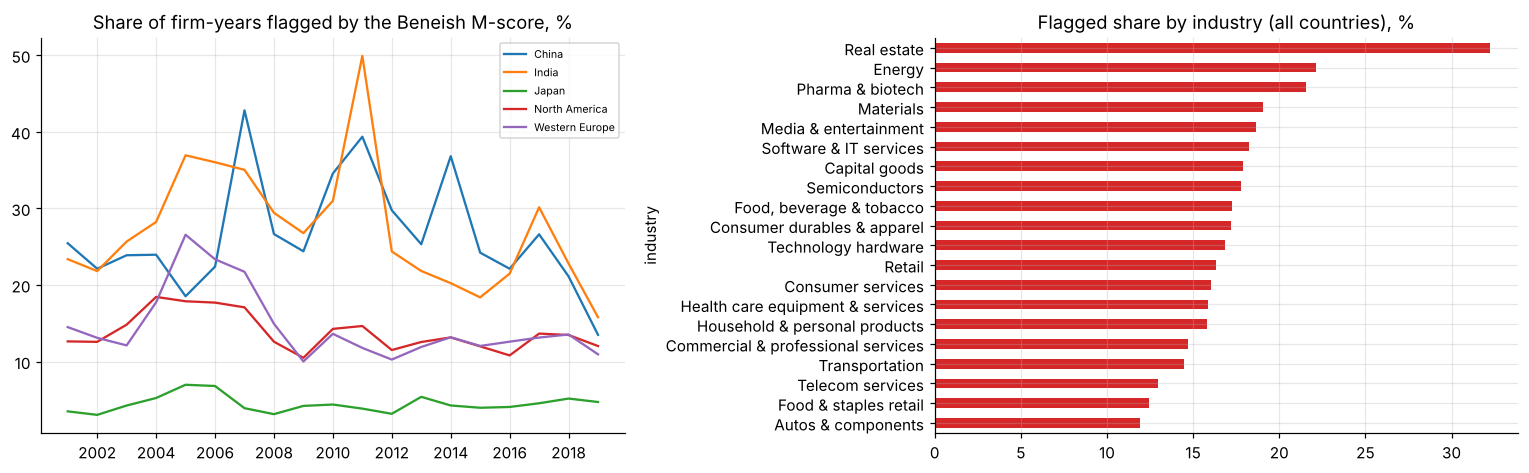

,m_flag,firms,firm_years
region,,,
North America,13.8,13908,117385
Western Europe,14.1,8453,94514
Japan,4.5,4261,58598
Other developed Asia-Pacific,19.7,9465,113375
China,26.0,4704,58149
India,27.1,3673,54194
OIC members,20.6,3511,48831
Other emerging,19.6,4817,62753


In [4]:
S, S1 = p.x_sale, lag("x_sale"); safe = lambda v: v.where(v > 0)
dsri = (p.x_rect / S) / (lag("x_rect") / S1)
gm, gm1 = (S - p.x_cogs) / S, (S1 - lag("x_cogs")) / S1; gmi = gm1 / gm
aq = 1 - (p.x_act + p.x_ppent) / p.x_at; aqi = aq / (1 - (lag("x_act") + lag("x_ppent")) / lag("x_at"))
sgi = S / safe(S1)
dep, dep1 = p.x_dp / (p.x_dp + p.x_ppent), lag("x_dp") / (lag("x_dp") + lag("x_ppent")); depi = dep1 / dep
sgai = (p.x_xsga / S) / (lag("x_xsga") / S1)
lvgi = ((p.x_dlc.fillna(0) + p.x_lct) / p.x_at) / ((lag("x_dlc").fillna(0) + lag("x_lct")) / lag("x_at"))
tata = (p.x_ib - p.x_oancf) / p.x_at
comp = pd.DataFrame({"DSRI": dsri, "GMI": gmi, "AQI": aqi, "SGI": sgi, "DEPI": depi, "SGAI": sgai, "LVGI": lvgi, "TATA": tata})
comp = comp.apply(lambda c: wins(c.where(np.isfinite(c))))
coef = {"DSRI": 0.920, "GMI": 0.528, "AQI": 0.404, "SGI": 0.892, "DEPI": 0.115, "SGAI": -0.172, "LVGI": -0.327, "TATA": 4.679}
p["mscore"] = -4.84 + sum(comp[k] * v for k, v in coef.items())
p["m_flag"] = (p.mscore > -1.78).astype(float).where(p.mscore.notna())
print(f"M-score computable for {p.mscore.notna().mean():.0%} of firm-years; {p.m_flag.mean():.1%} flagged overall")
mf = aggregate.summary(p, "region", ["m_flag"], stat="mean").reindex(REG_ORDER); mf["m_flag"] *= 100
mi = aggregate.summary(p, "industry", ["m_flag"], stat="mean").sort_values("m_flag"); mi["m_flag"] *= 100
my = p[p.region.isin(["North America", "Western Europe", "Japan", "China", "India"]) & p.fyear.le(2019)].groupby(["fyear", "region"]).m_flag.mean().unstack() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
my.iloc[1:].plot(ax=ax[0]); ax[0].set_title("Share of firm-years flagged by the Beneish M-score, %"); int_years(ax[0]); ax[0].legend(fontsize=7)
mi.m_flag.plot.barh(ax=ax[1], color="C3"); ax[1].set_title("Flagged share by industry (all countries), %")
plt.tight_layout(); plt.savefig(IMG / "beneish_mscore.png", bbox_inches="tight"); plt.show()
mf.join(mi.m_flag.rename("x"), how="left").drop(columns="x").to_csv(DATA / "beneish_flag_by_region.csv"); mf.round(1)

In [5]:
# does a flag predict what happens next? compare flagged and unflagged firms of the same country, industry and year
p["roa_chg2"] = lead("roa", 2) - p.roa
p["zombie_next"] = lead("zombie", 2)
p["loss_next"] = (lead("x_ib", 2) < 0).astype(float).where(lead("x_ib", 2).notna())
v = p.dropna(subset=["m_flag", "roa_chg2"]).copy()
for c in ["roa_chg2", "loss_next"]:
    v[c + "_adj"] = v[c] - v.groupby(["loc", "industry_group", "fyear"])[c].transform("mean")
val = v.groupby("m_flag")[["roa_chg2", "loss_next", "roa_chg2_adj", "loss_next_adj"]].mean().rename(index={0.0: "not flagged", 1.0: "flagged"}) * 100
val.columns = ["ROA change over 2 years, pts", "loss in year t+2, %", "ROA change vs peers, pts", "loss in t+2 vs peers, pts"]
val.to_csv(DATA / "beneish_validation.csv"); val.round(2)

,"ROA change over 2 years, pts","loss in year t+2, %","ROA change vs peers, pts","loss in t+2 vs peers, pts"
m_flag,,,,
not flagged,-0.18,25.85,0.39,-0.91
flagged,-2.93,32.40,-1.77,4.14


## 4 · Cost stickiness
Δln SG&A = β₀ + β₁·Δln Sales + β₂·D·Δln Sales, where D = 1 when sales fell. β₁ is the % change in SG&A for a 1% rise in sales; β₁ + β₂ for a 1% fall. β₂ < 0 means costs are sticky: managers cut them less when sales drop.

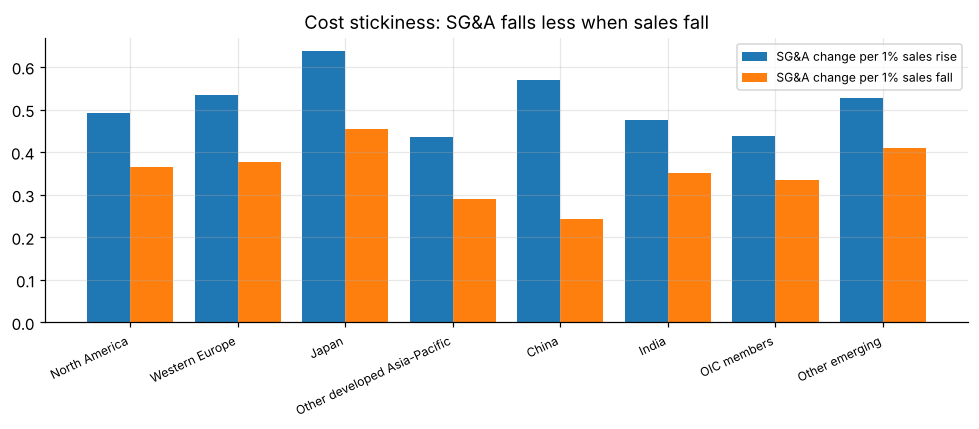

,beta1 (sales up),beta2 (extra when down),response when sales fall,t beta2,obs
region,,,,,
North America,0.49,-0.12,0.37,-11.47,83583
Western Europe,0.53,-0.16,0.38,-11.19,62955
Japan,0.64,-0.18,0.45,-10.95,53659
Other developed Asia-Pacific,0.44,-0.14,0.29,-13.39,87209
China,0.57,-0.33,0.24,-20.93,50606
India,0.48,-0.12,0.35,-7.05,41105
OIC members,0.44,-0.10,0.34,-5.93,39411
Other emerging,0.53,-0.12,0.41,-7.50,49706


In [6]:
import statsmodels.formula.api as smf
p["dl_sga"] = np.log(p.x_xsga.where(p.x_xsga > 0) / lag("x_xsga").where(lag("x_xsga") > 0))
p["dl_s"] = np.log(p.x_sale / safe(S1))
p["dec_dl_s"] = (p.dl_s < 0).astype(int) * p.dl_s
st = p.dropna(subset=["dl_sga", "dl_s"]); st = st[st.dl_sga.abs().lt(1) & st.dl_s.abs().lt(1)]
rows = []
for reg_, d in st.groupby("region"):
    m_ = smf.ols("dl_sga ~ dl_s + dec_dl_s", d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d.gvkey)[0]})
    rows.append((reg_, m_.params["dl_s"], m_.params["dec_dl_s"], m_.params["dl_s"] + m_.params["dec_dl_s"], m_.tvalues["dec_dl_s"], int(m_.nobs)))
stick = pd.DataFrame(rows, columns=["region", "beta1 (sales up)", "beta2 (extra when down)", "response when sales fall", "t beta2", "obs"]).set_index("region").reindex(REG_ORDER)
stick.to_csv(DATA / "cost_stickiness_by_region.csv")
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(stick)); ax.bar(x - 0.2, stick["beta1 (sales up)"], 0.4, label="SG&A change per 1% sales rise")
ax.bar(x + 0.2, stick["response when sales fall"], 0.4, label="SG&A change per 1% sales fall")
ax.set_xticks(x); ax.set_xticklabels(stick.index, rotation=25, ha="right", fontsize=8); ax.legend(fontsize=8); ax.set_title("Cost stickiness: SG&A falls less when sales fall")
plt.tight_layout(); plt.savefig(IMG / "cost_stickiness.png", bbox_inches="tight"); plt.show()
stick.round(3)

## 5 · Effective tax rates
Tax expense divided by pre-tax income (net income + tax), for firms with positive pre-tax income, capped between 0 and 100%.

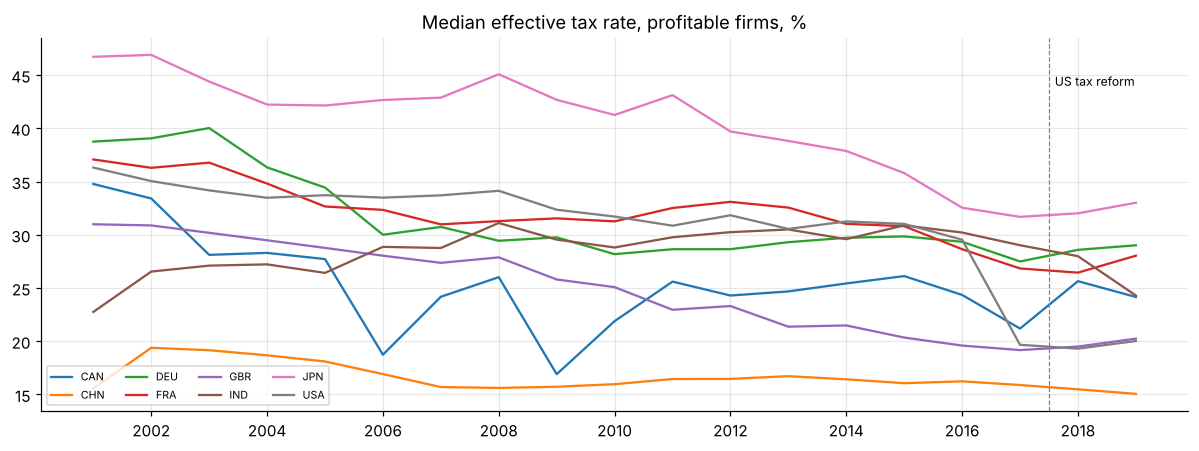

US median ETR 2015-2017 vs 2018-2019: 28.2 -> 19.6


,etr,firms,firm_years
loc,,,
ARE,0.0,55,154
KWT,1.1,73,212
BMU,9.9,52,141
SAU,10.0,130,383
BGR,10.2,51,146
ROU,14.1,98,284
CYP,14.1,55,145
JOR,14.4,92,255
ITA,28.3,298,834


In [7]:
pti = p.x_ib + p.x_txt
p["etr"] = (p.x_txt / pti.where(pti > 0)).clip(0, 1)
etr_y = p[p["loc"].isin(["USA", "GBR", "DEU", "FRA", "JPN", "CHN", "IND", "CAN"]) & p.fyear.between(2001, 2019)].groupby(["fyear", "loc"]).etr.median().unstack() * 100
fig, ax = plt.subplots(figsize=(11, 4.2))
etr_y.plot(ax=ax); ax.axvline(2017.5, color="grey", ls="--", lw=0.8); ax.text(2017.6, 44, "US tax reform", fontsize=8)
ax.set_title("Median effective tax rate, profitable firms, %"); int_years(ax); ax.legend(fontsize=7, ncol=4, loc="lower left")
plt.tight_layout(); plt.savefig(IMG / "effective_tax_rates.png", bbox_inches="tight"); plt.show()
etr_c = aggregate.summary(p[p.fyear.between(2017, 2019)], "loc", ["etr"], min_firms=50).sort_values("etr"); etr_c["etr"] *= 100
etr_c.to_csv(DATA / "effective_tax_rate_by_country_2017_2019.csv")
print("US median ETR 2015-2017 vs 2018-2019:", round(100 * p[p["loc"].eq("USA") & p.fyear.between(2015, 2017)].etr.median(), 1), "->",
      round(100 * p[p["loc"].eq("USA") & p.fyear.between(2018, 2019)].etr.median(), 1))
pd.concat([etr_c.head(8), etr_c.tail(8)]).round(1)

## Findings
* **Accruals are less persistent than cash flows everywhere outside India.** One unit of operating cash flow carries 0.86 into next year's earnings in North America, against 0.53 for one unit of accruals. That 0.33 gap is the basis of the Sloan accrual anomaly. The gap is smaller in China (0.14) and emerging markets, and absent in India.
* **Discretionary accruals are lowest in Japan (2.7% of assets)** and Saudi Arabia, and highest in Australia (9.1%), Nigeria, Vietnam, Poland and Ireland. They are unrelated to national income (rank correlation -0.09). Australia, Canada and Hong Kong rank high because of their many small mining and resource companies.
* **The Beneish M-score flags 17.6% of firm-years worldwide:** 4.5% in Japan, about 14% in North America and Western Europe, and 26-27% in China and India. Real estate (32%), energy (22%) and pharma (22%) are flagged most. India's flag rate peaked at 50% in 2011.
* **A flag is a real warning sign.** Against firms of the same country, industry and year, flagged firms' ROA falls 1.8 points more over the next two years, and they are 4.1 points more likely to report a loss two years later.
* **Costs are sticky everywhere.** SG&A rises 0.49% for each 1% sales rise in North America but falls only 0.37% for a 1% decline (t = -11). Chinese firms are the stickiest (0.57 up, 0.24 down). Firms in OIC member markets adjust most evenly (0.44 up, 0.34 down). For CFOs this is the case for building variable-cost structures before a downturn, not during it.
* **Effective tax rates converged downward.** Japan fell from 47% to 33% and Germany from 39% to 29% (2001-2019). The US median fell from 28.2% (2015-2017) to 19.6% (2018-2019) after the 2017 tax reform, the sharpest single change in the data. China's median has held near 15-16%, the preferential rate for high-tech firms.